In [14]:
import numpy as np
import matplotlib.pyplot as plt


def cosine_similarity(a, b, eps=1e-8):
    return np.sum(a * b, axis=-1) / (
        np.linalg.norm(a, axis=-1) * np.linalg.norm(b, axis=-1) + eps
    )


def analyze_adjacent_step_cosine(velocities):
    """
    velocities: [B, N, H, D]
    return:
        cos_all: [B, N-1]
        mean_cos: [N-1]
    """
    B, N, H, D = velocities.shape

    # flatten action chunk and action dim
    v = velocities.reshape(B, N, H * D)

    cos_all = []

    for n in range(N - 1):
        cos_n = cosine_similarity(v[:, n, :], v[:, n + 1, :])  # [B]
        cos_all.append(cos_n)

    cos_all = np.stack(cos_all, axis=1)  # [B, N-1]
    mean_cos = cos_all.mean(axis=0)      # [N-1]

    return cos_all, mean_cos




In [15]:
import numpy as np
import matplotlib.pyplot as plt


def pairwise_cosine_disagreement(vectors, eps=1e-8):
    """
    vectors: [B, D]
    Compare velocity directions across B samples.
    """
    B = vectors.shape[0]

    if B < 2:
        return np.nan, np.nan

    cos_values = []

    for i in range(B):
        for j in range(i + 1, B):
            vi = vectors[i]
            vj = vectors[j]

            cos = np.dot(vi, vj) / (
                np.linalg.norm(vi) * np.linalg.norm(vj) + eps
            )
            cos_values.append(cos)

    mean_cosine = np.mean(cos_values)
    disagreement = 1.0 - mean_cosine

    return disagreement, mean_cosine


def cosine_similarity_batch(a, b, eps=1e-8):
    """
    a, b: [B, D]
    return: [B]
    """
    return np.sum(a * b, axis=-1) / (
        np.linalg.norm(a, axis=-1) * np.linalg.norm(b, axis=-1) + eps
    )


def analyze_each_h_velocity(velocities):
    """
    velocities: [H, N, B, D]

    H: action chunk index
    N: denoising steps
    B: batch / repeated samples
    D: action dimension
    """
    velocities = np.asarray(velocities)

    H, N, B, D = velocities.shape

    reports = []

    for h in range(H):
        # v_h: [N, B, D]
        v_h = velocities[h]

        # ----------------------------------
        # 1. Cross-sample disagreement per denoising step
        # ----------------------------------
        disagreement_per_step = []
        mean_cosine_per_step = []

        for n in range(N):
            # v_h[n]: [B, D]
            disagreement, mean_cosine = pairwise_cosine_disagreement(v_h[n])
            disagreement_per_step.append(disagreement)
            mean_cosine_per_step.append(mean_cosine)

        disagreement_per_step = np.array(disagreement_per_step)
        mean_cosine_per_step = np.array(mean_cosine_per_step)

        flow_uncertainty = np.nanmean(disagreement_per_step)

        # ----------------------------------
        # 2. Adjacent-step jitter
        # ----------------------------------
        adjacent_cos_all = []

        for n in range(N - 1):
            # compare v_h[n] and v_h[n+1], both [B, D]
            # print(f"v shape: {v_h[n].shape}, {v_h[n+1].shape}")
            cos_n = cosine_similarity_batch(v_h[n], v_h[n + 1])  # [B]
            adjacent_cos_all.append(cos_n)

        adjacent_cos_all = np.stack(adjacent_cos_all, axis=0)  # [N-1, B]
        mean_adjacent_cos = adjacent_cos_all.mean(axis=1)      # [N-1]

        jitter_score = 1.0 - mean_adjacent_cos.mean()

        # ----------------------------------
        # 3. Variance over B
        # ----------------------------------
        # var over samples: [N, D]
        var_step_dim = np.var(v_h, axis=1)

        # average over denoising steps: [D]
        dim_uncertainty = var_step_dim.mean(axis=0)

        # average over action dimensions: [N]
        step_variance = var_step_dim.mean(axis=-1)

        reports.append({
            "h": h,
            "flow_uncertainty": float(flow_uncertainty),
            "jitter_score": float(jitter_score),
            "disagreement_per_step": disagreement_per_step,
            "mean_cosine_per_step": mean_cosine_per_step,
            "mean_adjacent_cos": mean_adjacent_cos,
            "var_step_dim": var_step_dim,
            "dim_uncertainty": dim_uncertainty,
            "step_variance": step_variance,
        })

    return reports

In [16]:
def plot_h_summary(reports_h):
    h_list = [r["h"] for r in reports_h]
    flow_uncertainties = [r["flow_uncertainty"] for r in reports_h]
    jitter_scores = [r["jitter_score"] for r in reports_h]

    plt.figure(figsize=(12, 4))
    plt.plot(h_list, flow_uncertainties, marker="o")
    plt.xlabel("Action chunk index H")
    plt.ylabel("Flow uncertainty")
    plt.title("Flow-level uncertainty for each action chunk step")
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(12, 4))
    plt.plot(h_list, jitter_scores, marker="o")
    plt.xlabel("Action chunk index H")
    plt.ylabel("Jitter score")
    plt.title("Velocity jitter for each action chunk step")
    plt.grid(True)
    plt.show()

In [20]:
def plot_each_h_disagreement(reports_h):
    plt.figure(figsize=(8, 5))

    for r in reports_h:
        plt.plot(
            r["disagreement_per_step"],
            marker="o",
            label=f"H={r['h']}"
        )

    plt.xlabel("Denoising step")
    plt.ylabel("Cross-sample velocity disagreement")
    plt.title("Velocity disagreement per H across denoising steps")
    plt.grid(True)
    plt.legend()
    plt.show()

Original shape: (163, 10, 20, 7)


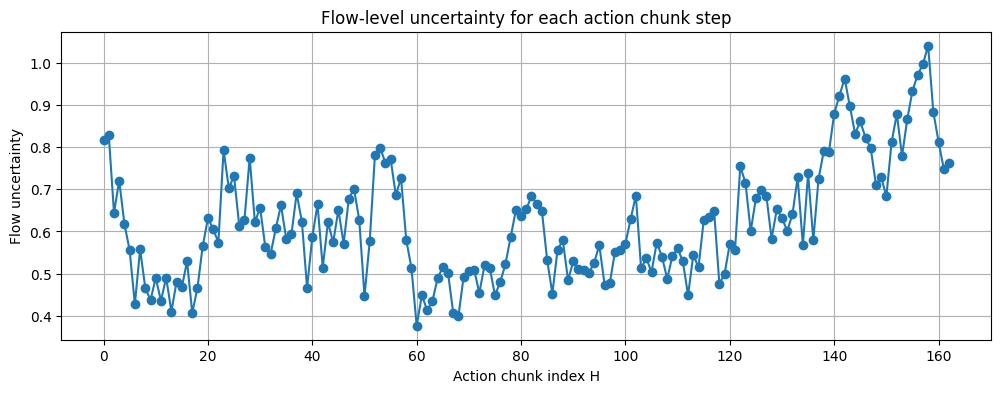

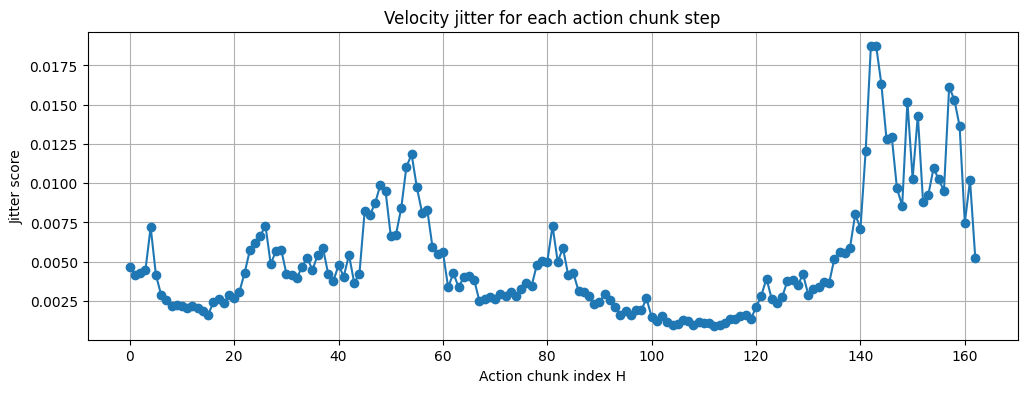

In [21]:
data_8 = np.load("../outputs/libero_eval_velocities_1/episodes_npz/task_008_episode_001.npz")
velocities_numpy = data_8["velocitys"][:,:,:,:7]  # [h, N, b, D]
print("Original shape:", velocities_numpy.shape)
reports_h = analyze_each_h_velocity(velocities_numpy)

# for r in reports_h:
#     print(
#         f"H={r['h']} | "
#         f"flow_uncertainty={r['flow_uncertainty']:.6f} | "
#         f"jitter_score={r['jitter_score']:.6f}"
#     )
plot_h_summary(reports_h)
jitter_scores_8 = [r["jitter_score"] for r in reports_h]

Original shape: (300, 10, 20, 7)


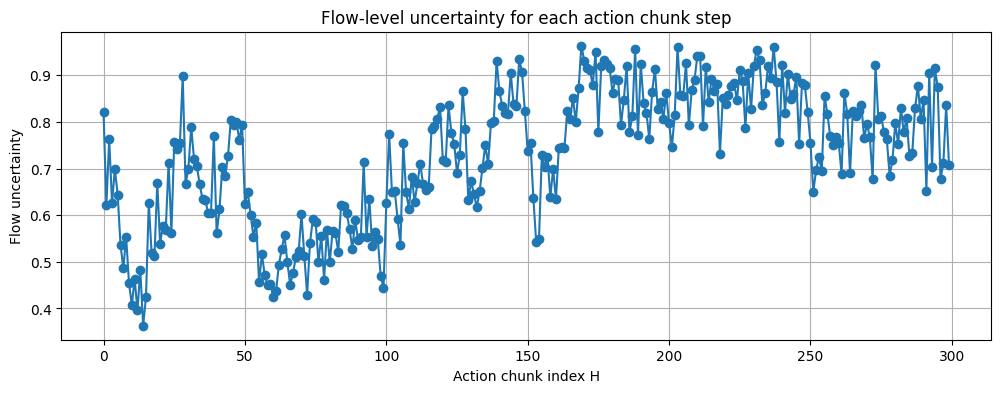

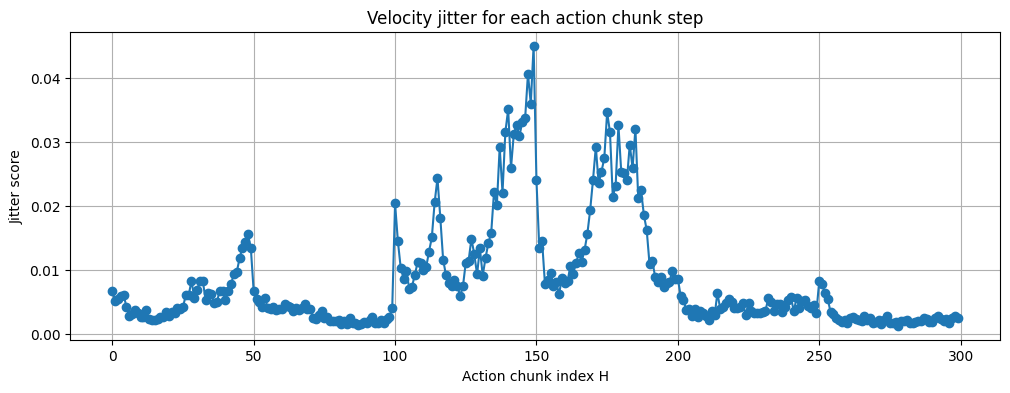

In [22]:
data_7 = np.load("../outputs/libero_eval_velocities_1/episodes_npz/task_007_episode_000.npz")
velocities_numpy = data_7["velocitys"][:,:,:,:7]  # [h, N, b, D]
print("Original shape:", velocities_numpy.shape)
reports_h = analyze_each_h_velocity(velocities_numpy)

# for r in reports_h:
#     print(
#         f"H={r['h']} | "
#         f"flow_uncertainty={r['flow_uncertainty']:.6f} | "
#         f"jitter_score={r['jitter_score']:.6f}"
#     )
plot_h_summary(reports_h)
jitter_scores_7 = [r["jitter_score"] for r in reports_h]

Original shape: (133, 10, 20, 7)


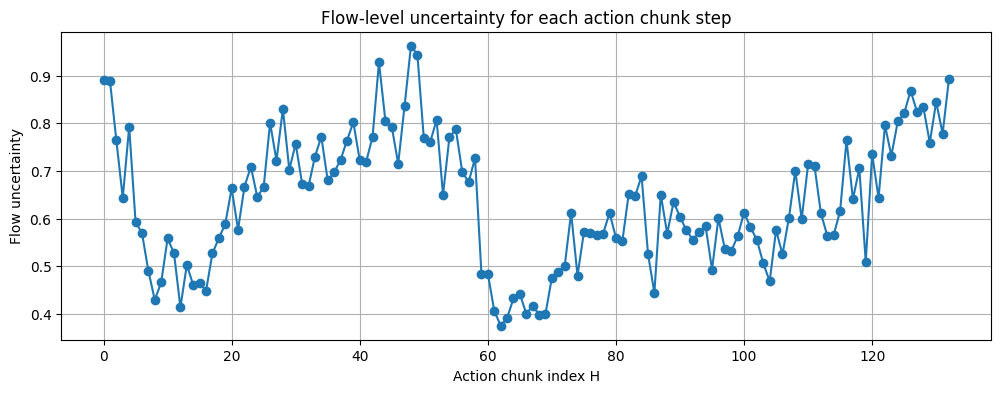

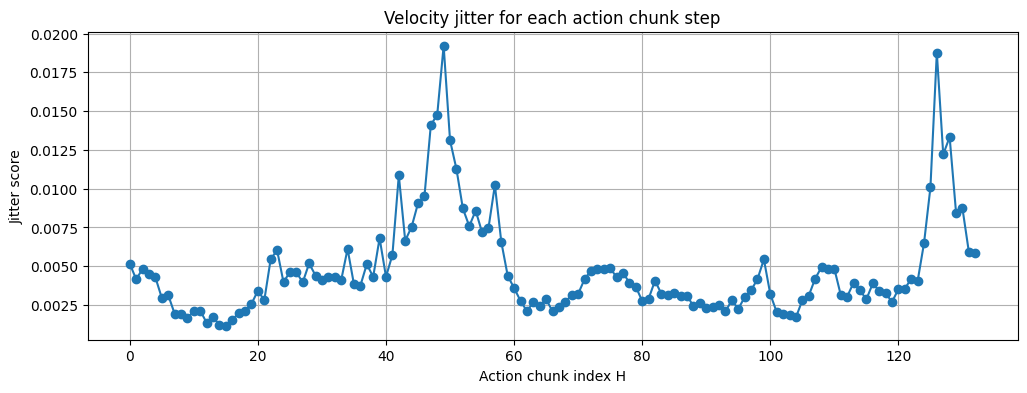

In [23]:
data_9 = np.load("../outputs/libero_eval_velocities_1/episodes_npz/task_009_episode_002.npz")
velocities_numpy = data_9["velocitys"][:,:,:,:7]  # [h, N, b, D]
print("Original shape:", velocities_numpy.shape)
reports_h = analyze_each_h_velocity(velocities_numpy)

# for r in reports_h:
#     print(
#         f"H={r['h']} | "
#         f"flow_uncertainty={r['flow_uncertainty']:.6f} | "
#         f"jitter_score={r['jitter_score']:.6f}"
#     )
plot_h_summary(reports_h)
jitter_scores_9 = [r["jitter_score"] for r in reports_h]

In [24]:
data_new["velocitys"][1,:,0,:7]

array([[-1.86258650e+00,  4.57670763e-02,  7.11229384e-01,
         2.03861547e+00, -6.89885914e-01,  1.59816146e+00,
        -2.33000040e-01],
       [-1.80354452e+00,  9.91766527e-02,  6.35017097e-01,
         1.99985743e+00, -6.47456169e-01,  1.60905671e+00,
        -2.27040470e-01],
       [-1.85091901e+00,  2.05774959e-02,  5.77558458e-01,
         2.02836299e+00, -5.75386047e-01,  1.66871727e+00,
        -1.86933756e-01],
       [-1.85243714e+00,  4.55101803e-02,  4.64399993e-01,
         1.97478986e+00, -6.15208089e-01,  1.80912185e+00,
        -1.69717759e-01],
       [-1.85686636e+00, -8.91500153e-03,  4.49063838e-01,
         1.97379398e+00, -6.66442275e-01,  1.92782080e+00,
        -1.65949166e-01],
       [-1.79945767e+00, -1.76608507e-02,  4.64292794e-01,
         1.94487202e+00, -6.69646442e-01,  2.08971429e+00,
        -1.56733528e-01],
       [-1.70394480e+00,  1.79356895e-03,  5.25220692e-01,
         1.92310679e+00, -6.08924568e-01,  2.17830920e+00,
        -1.4057973

In [25]:
import numpy as np
import matplotlib.pyplot as plt


def analyze_action_uncertainty(actions, action_dim_names=None):
    """
    actions: [steps, batch, action_dims]
    """
    actions = np.asarray(actions)

    if actions.ndim != 3:
        raise ValueError(
            f"Expected actions shape [steps, batch, action_dims], got {actions.shape}"
        )

    T, B, D = actions.shape

    if action_dim_names is None:
        if D == 7:
            action_dim_names = ["dx", "dy", "dz", "dRx", "dRy", "dRz", "grip"]
        elif D == 4:
            action_dim_names = ["dx", "dy", "dz", "grip"]
        else:
            action_dim_names = [f"dim{i}" for i in range(D)]

    # mean action per step: [T, D]
    mean_action = actions.mean(axis=1)

    # variance over batch: [T, D]
    var_action = actions.var(axis=1)

    # std over batch: [T, D]
    std_action = actions.std(axis=1)

    # average variance per step: [T]
    step_uncertainty_var = var_action.mean(axis=1)

    # average std per step: [T]
    step_uncertainty_std = std_action.mean(axis=1)

    # max dimension variance per step: [T]
    step_uncertainty_max_dim = var_action.max(axis=1)

    # action range over batch: [T, D]
    range_action = actions.max(axis=1) - actions.min(axis=1)

    # average range per step: [T]
    step_uncertainty_range = range_action.mean(axis=1)

    report = {
        "shape": {
            "steps": T,
            "batch": B,
            "action_dims": D,
        },
        "mean_action": mean_action,
        "var_action": var_action,
        "std_action": std_action,
        "range_action": range_action,
        "step_uncertainty_var": step_uncertainty_var,
        "step_uncertainty_std": step_uncertainty_std,
        "step_uncertainty_max_dim": step_uncertainty_max_dim,
        "step_uncertainty_range": step_uncertainty_range,
        "action_dim_names": action_dim_names,
    }

    return report

In [26]:
def plot_step_uncertainty(report):
    step_uncertainty_var = report["step_uncertainty_var"]
    step_uncertainty_std = report["step_uncertainty_std"]
    step_uncertainty_range = report["step_uncertainty_range"]

    steps = np.arange(len(step_uncertainty_var))

    plt.figure(figsize=(12, 4))
    plt.plot(steps, step_uncertainty_var, label="mean variance")
    plt.xlabel("Trajectory step")
    plt.ylabel("Action uncertainty")
    plt.title("Per-step action uncertainty")
    plt.grid(True)
    plt.legend()
    plt.show()

    plt.figure(figsize=(12, 4))
    plt.plot(steps, step_uncertainty_std, label="mean std")
    plt.xlabel("Trajectory step")
    plt.ylabel("Action std")
    plt.title("Per-step action standard deviation")
    plt.grid(True)
    plt.legend()
    plt.show()

    plt.figure(figsize=(12, 4))
    plt.plot(steps, step_uncertainty_range, label="mean range")
    plt.xlabel("Trajectory step")
    plt.ylabel("Action range")
    plt.title("Per-step action range across sampled actions")
    plt.grid(True)
    plt.legend()
    plt.show()

In [27]:
def plot_action_dim_uncertainty(report):
    var_action = report["var_action"]  # [T, D]
    action_dim_names = report["action_dim_names"]

    T, D = var_action.shape

    plt.figure(figsize=(12, 5))
    for d in range(D):
        plt.plot(var_action[:, d], label=action_dim_names[d])

    plt.xlabel("Trajectory step")
    plt.ylabel("Variance over sampled actions")
    plt.title("Per-dimension action uncertainty over trajectory")
    plt.grid(True)
    plt.legend()
    plt.show()

In [28]:
report_9 = analyze_action_uncertainty(data_9["raw_actions"][:,:, :6 ])

print(report_9["shape"])
print("Mean step uncertainty:", report_9["step_uncertainty_var"].mean())
print("Max step uncertainty:", report_9["step_uncertainty_var"].max())
# plot_step_uncertainty(report_9)
step_uncertainty_std_9 = report_9["step_uncertainty_std"]

{'steps': 133, 'batch': 20, 'action_dims': 6}
Mean step uncertainty: 0.05214582157101763
Max step uncertainty: 0.15936139829999516


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

def analyze_correlation(x, y, name_x="flow_uncertainty", name_y="jitter_score"):
    x = np.asarray(x).reshape(-1)
    y = np.asarray(y).reshape(-1)

    # 对齐长度
    n = min(len(x), len(y))
    x = x[:n]
    y = y[:n]

    # 去掉 NaN / Inf
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    print("=" * 50)
    print(f"Correlation between {name_x} and {name_y}")
    print("=" * 50)
    print("valid length:", len(x))

    pearson_corr, pearson_p = pearsonr(x, y)
    spearman_corr, spearman_p = spearmanr(x, y)

    print(f"Pearson correlation : {pearson_corr:.4f}, p = {pearson_p:.4e}")
    print(f"Spearman correlation: {spearman_corr:.4f}, p = {spearman_p:.4e}")

    # 画时间序列，对比趋势
    plt.figure(figsize=(10, 4))
    plt.plot(x, label=name_x)
    plt.plot(y, label=name_y)
    plt.xlabel("step")
    plt.ylabel("value")
    plt.title("Time-series comparison")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # 画散点图
    plt.figure(figsize=(5, 5))
    plt.scatter(x, y, alpha=0.7)
    plt.xlabel(name_x)
    plt.ylabel(name_y)
    plt.title(f"Scatter plot\nPearson={pearson_corr:.3f}, Spearman={spearman_corr:.3f}")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return {
        "pearson": pearson_corr,
        "pearson_p": pearson_p,
        "spearman": spearman_corr,
        "spearman_p": spearman_p,
    }

In [29]:
result = analyze_correlation(
    step_uncertainty_std_9,
    jitter_scores_9,
    name_x="step_uncertainty_std",
    name_y="jitter_scores"
)

NameError: name 'analyze_correlation' is not defined

{'steps': 300, 'batch': 20, 'action_dims': 7}
Mean step uncertainty: 0.06893469824204299
Max step uncertainty: 0.44193432326987286
Correlation between step_uncertainty_std and jitter_scores
valid length: 300
Pearson correlation : 0.6983, p = 3.5346e-45
Spearman correlation: 0.5858, p = 5.0121e-29


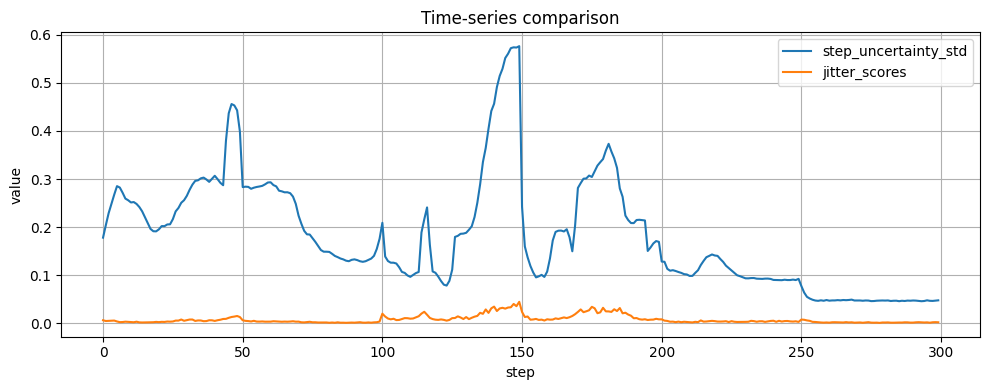

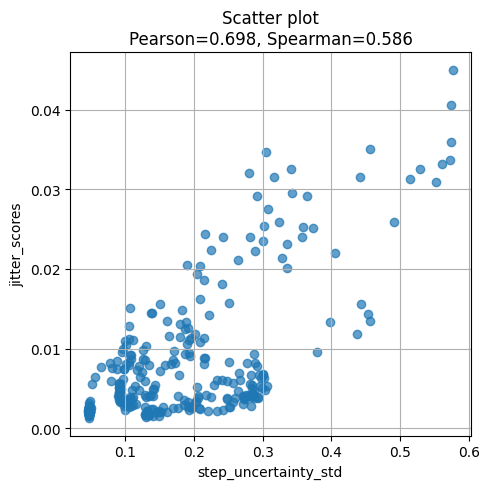

In [ ]:
report_7 = analyze_action_uncertainty(data_7["raw_actions"][:,:, :7 ])

print(report_7["shape"])
print("Mean step uncertainty:", report_7["step_uncertainty_var"].mean())
print("Max step uncertainty:", report_7["step_uncertainty_var"].max())
# plot_step_uncertainty(report_7)
step_uncertainty_std_7 = report_7["step_uncertainty_std"]
result = analyze_correlation(
    step_uncertainty_std_7,
    jitter_scores_7,
    name_x="step_uncertainty_std",
    name_y="jitter_scores"
)

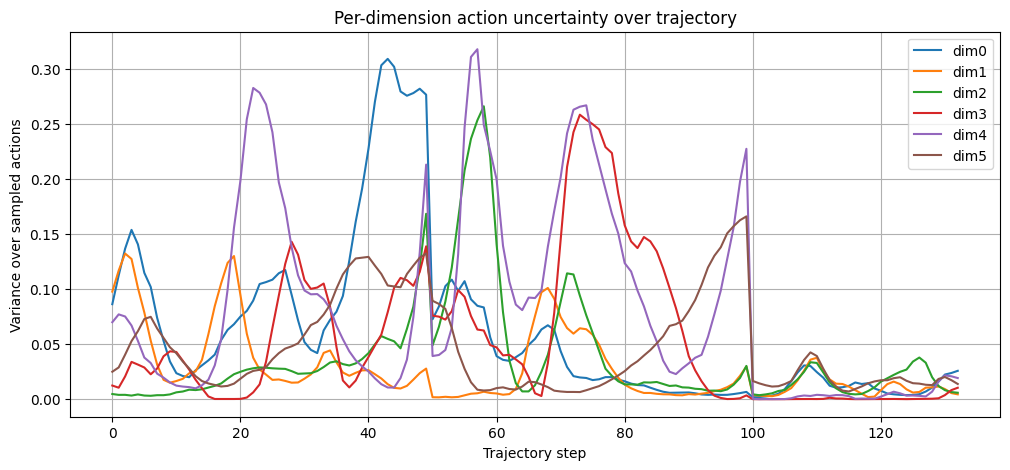

In [ ]:
plot_action_dim_uncertainty(report_9)

{'steps': 145, 'batch': 20, 'action_dims': 7}
Mean step uncertainty: 0.053545844400483586
Max step uncertainty: 0.2471794132007382


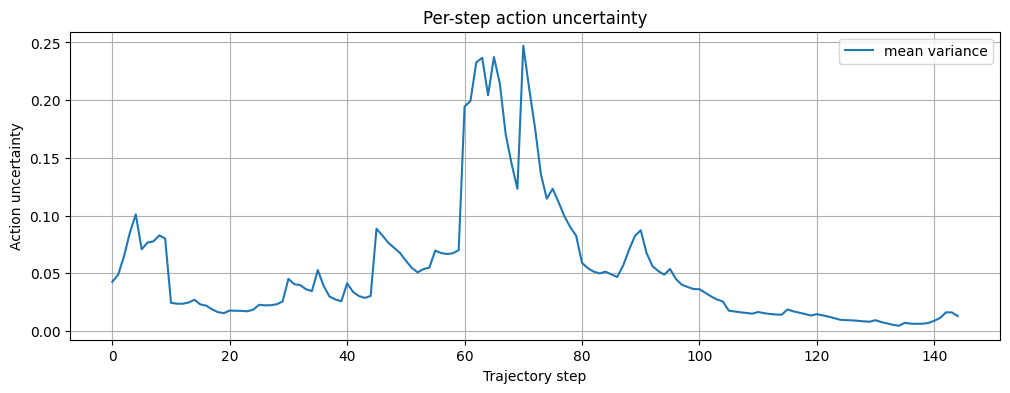

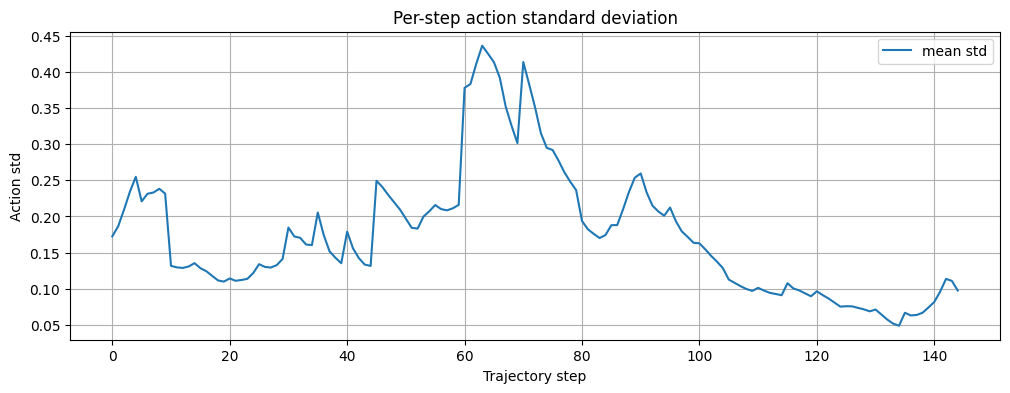

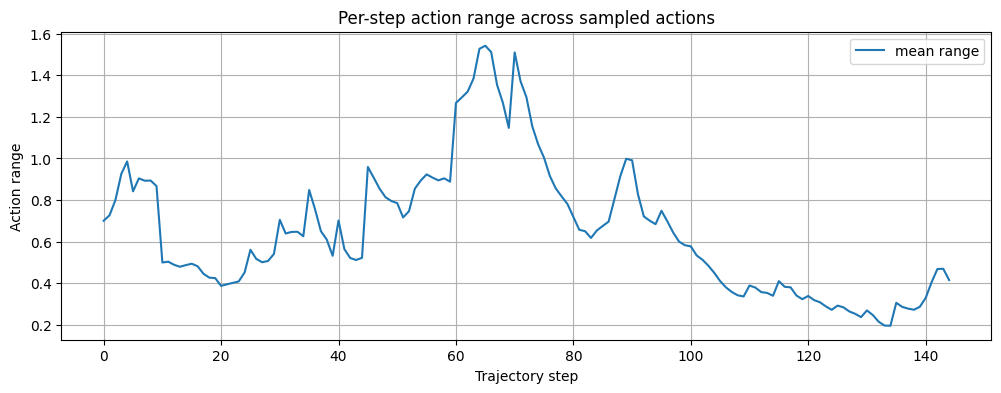

In [ ]:
report_new= analyze_action_uncertainty(data_new["raw_actions"])

print(report_new["shape"])
print("Mean step uncertainty:", report_new["step_uncertainty_var"].mean())
print("Max step uncertainty:", report_new["step_uncertainty_var"].max())
plot_step_uncertainty(report_new)

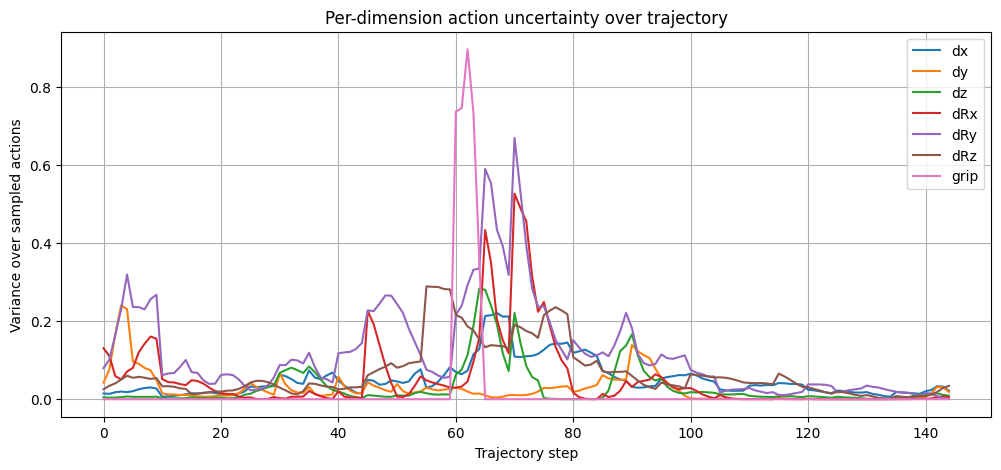

In [ ]:
plot_action_dim_uncertainty(report_new)

In [ ]:
import numpy as np

last = data_9["actions"][:, -1]

idx_neg_to_pos = np.where((last[:-1] == -1) & (last[1:] == 1))[0]

print(idx_neg_to_pos)
print("transition pairs:")
for i in idx_neg_to_pos:
    print(i, "->", i + 1, last[i], "->", last[i + 1])

NameError: name 'data_9' is not defined

In [30]:
def plot_action_uncertainty_heatmap(report):
    var_action = report["var_action"]  # [T, D]
    action_dim_names = report["action_dim_names"]

    T, D = var_action.shape

    plt.figure(figsize=(8, 6))
    plt.imshow(var_action.T, aspect="auto")
    plt.colorbar(label="Variance over sampled actions")
    plt.xlabel("Trajectory step")
    plt.ylabel("Action dimension")
    plt.title("Action uncertainty heatmap")
    plt.yticks(np.arange(D), action_dim_names)
    plt.show()

In [31]:
def print_top_uncertain_steps(report, top_k=10):
    step_uncertainty = report["step_uncertainty_var"]
    var_action = report["var_action"]
    action_dim_names = report["action_dim_names"]

    top_idx = np.argsort(step_uncertainty)[::-1][:top_k]

    print(f"Top {top_k} uncertain steps:")
    for t in top_idx:
        print(
            f"\nstep={t}, "
            f"uncertainty={step_uncertainty[t]:.6f}"
        )

        dim_order = np.argsort(var_action[t])[::-1]
        for d in dim_order[:3]:
            print(
                f"  {action_dim_names[d]}: var={var_action[t, d]:.6f}"
            )

In [ ]:
print_top_uncertain_steps(report_9, top_k=10)

Top 10 uncertain steps:

step=49, uncertainty=0.159361
  dim0: var=0.276263
  dim4: var=0.212858
  dim2: var=0.168254

step=48, uncertainty=0.133699
  dim0: var=0.281671
  dim4: var=0.133054
  dim5: var=0.128411

step=56, uncertainty=0.122234
  dim4: var=0.310503
  dim2: var=0.236259
  dim0: var=0.090671

step=57, uncertainty=0.122118
  dim4: var=0.317515
  dim2: var=0.253058
  dim0: var=0.084781

step=73, uncertainty=0.118033
  dim4: var=0.265371
  dim3: var=0.258120
  dim2: var=0.093995

step=72, uncertainty=0.117548
  dim4: var=0.262643
  dim3: var=0.242287
  dim2: var=0.113213

step=74, uncertainty=0.114561
  dim4: var=0.266623
  dim3: var=0.253519
  dim2: var=0.076195

step=55, uncertainty=0.114221
  dim4: var=0.246543
  dim2: var=0.207491
  dim0: var=0.107122

step=47, uncertainty=0.112966
  dim0: var=0.277744
  dim5: var=0.121202
  dim3: var=0.102882

step=58, uncertainty=0.112513
  dim2: var=0.265779
  dim4: var=0.248837
  dim0: var=0.083295


In [32]:
def pairwise_cosine_disagreement(vectors, eps=1e-8):
    """
    vectors: [B, D]
    """
    B = vectors.shape[0]

    if B < 2:
        return np.nan, np.nan

    cos_values = []

    for i in range(B):
        for j in range(i + 1, B):
            vi = vectors[i]
            vj = vectors[j]

            cos = np.dot(vi, vj) / (
                np.linalg.norm(vi) * np.linalg.norm(vj) + eps
            )
            cos_values.append(cos)

    mean_cos = np.mean(cos_values)
    disagreement = 1.0 - mean_cos

    return disagreement, mean_cos


def compute_action_direction_uncertainty(actions):
    """
    actions: [T, B, D]
    return:
        direction_uncertainty: [T]
        mean_cosine: [T]
    """
    actions = np.asarray(actions)
    T, B, D = actions.shape

    direction_uncertainty = []
    mean_cosine = []

    for t in range(T):
        u, c = pairwise_cosine_disagreement(actions[t])
        direction_uncertainty.append(u)
        mean_cosine.append(c)

    return np.array(direction_uncertainty), np.array(mean_cosine)

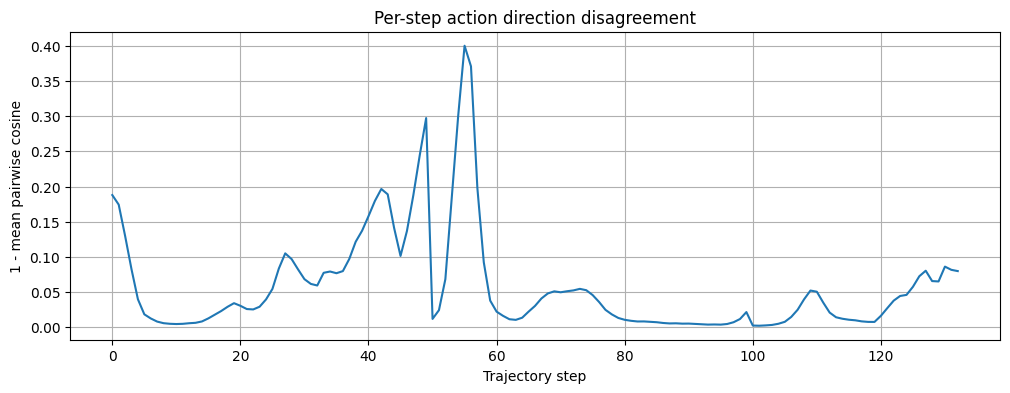

In [ ]:
# direction_uncertainty, mean_cosine = compute_action_direction_uncertainty(data_9["raw_actions"][:,:, :6])
motion_actions = data_9["raw_actions"][:, :, :3] 
direction_uncertainty, mean_cosine = compute_action_direction_uncertainty(motion_actions)

plt.figure(figsize=(12, 4))
plt.plot(direction_uncertainty)
plt.xlabel("Trajectory step")
plt.ylabel("1 - mean pairwise cosine")
plt.title("Per-step action direction disagreement")
plt.grid(True)
plt.show()

Data loaded.NpzFile '../outputs/libero_eval_velocities_4/episodes_npz/task_008_episode_008.npz' with keys: task_description, initial_state, task_id, episode_idx, success...
task_description () object
initial_state (110,) float64
task_id () int32
episode_idx () int32
success () bool
actions (300, 7) float32
raw_actions (300, 3, 7) float64
attention_maps (300,) object
front_images (300, 256, 256, 3) uint8
wrist_images (300, 256, 256, 3) uint8
velocitys (300, 10, 3, 7) object
nll_steps (300, 3) object
nll_totals (300, 3) object
Original shape: (300, 10, 3, 7)


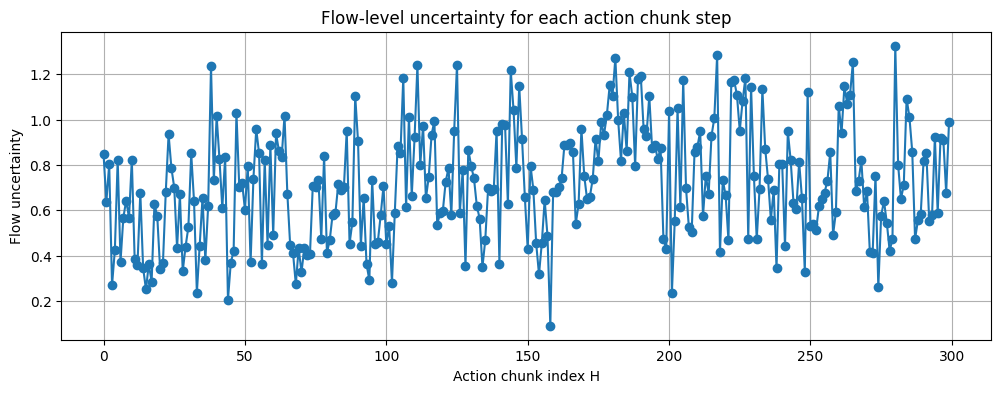

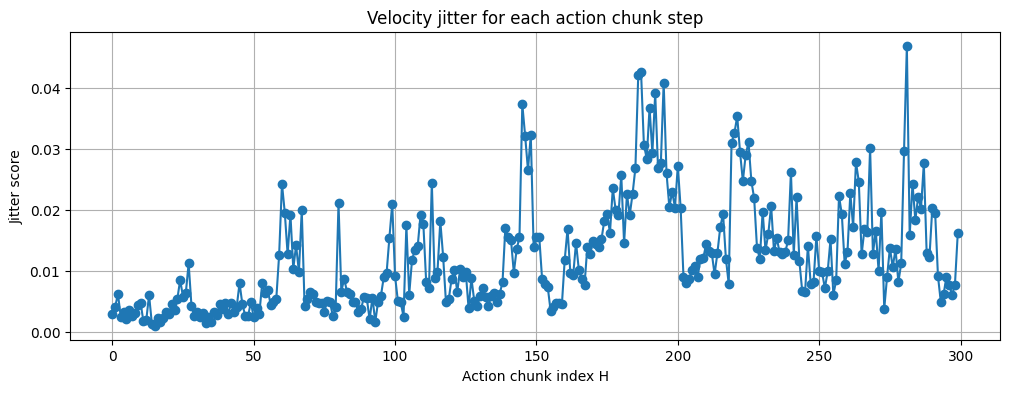

In [ ]:
data_1 = np.load("../outputs/libero_eval_velocities_4/episodes_npz/task_008_episode_008.npz",allow_pickle=True)
print(f"Data loaded.{data_1}")
for key in data_1.keys():
    arr = data_1[key]
    print(key, arr.shape, arr.dtype)
velocities_numpy = data_1["velocitys"][:,:,:,:7]  # [h, N, b, D]
velocities_numpy = np.asarray(velocities_numpy, dtype=np.float32)
print("Original shape:", velocities_numpy.shape)
reports_h = analyze_each_h_velocity(velocities_numpy)

plot_h_summary(reports_h)

In [65]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import math

def reports_to_arrays(reports_h):
    h_list = np.asarray([r["h"] for r in reports_h])
    flow_uncertainties = np.asarray([r["flow_uncertainty"] for r in reports_h], dtype=np.float32)
    jitter_scores = np.asarray([r["jitter_score"] for r in reports_h], dtype=np.float32)

    return h_list, flow_uncertainties, jitter_scores


def plot_all_npz_h_summary(
    npz_dir="../outputs/libero_eval_velocities_4/episodes_npz",
    ncols=3,
    figsize_per_plot=(5, 3),
    max_files=None,
    save_path=None,
):
    npz_dir = Path(npz_dir)
    files = sorted(npz_dir.glob("*.npz"))

    if max_files is not None:
        files = files[:max_files]

    if len(files) == 0:
        print(f"No npz files found in: {npz_dir}")
        return

    n_files = len(files)
    nrows = math.ceil(n_files / ncols)

    # -------------------------
    # Figure 1: flow uncertainty
    # -------------------------
    fig1, axes1 = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(figsize_per_plot[0] * ncols, figsize_per_plot[1] * nrows),
        squeeze=False,
    )

    # -------------------------
    # Figure 2: jitter score
    # -------------------------
    fig2, axes2 = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(figsize_per_plot[0] * ncols, figsize_per_plot[1] * nrows),
        squeeze=False,
    )

    for idx, file_path in enumerate(files):
        row = idx // ncols
        col = idx % ncols

        data = np.load(file_path, allow_pickle=True)

        if "velocitys" not in data:
            print(f"Skip {file_path.name}: no velocitys key")
            continue

        velocities_numpy = data["velocitys"][:, :, :, :7]
        velocities_numpy = np.asarray(velocities_numpy, dtype=np.float32)

        reports_h = analyze_each_h_velocity(velocities_numpy)
        h_list, flow_uncertainties, jitter_scores = reports_to_arrays(reports_h)

        ax1 = axes1[row][col]
        ax1.plot(h_list, flow_uncertainties, marker="o", linewidth=1.2)
        ax1.set_title(file_path.stem, fontsize=9)
        ax1.set_xlabel("Trajectory step")
        ax1.set_ylabel("Flow uncertainty")
        ax1.grid(True, alpha=0.3)

        ax2 = axes2[row][col]
        ax2.plot(h_list, jitter_scores, marker="o", linewidth=1.2)
        ax2.set_title(file_path.stem, fontsize=9)
        ax2.set_xlabel("Trajectory step")
        ax2.set_ylabel("Jitter score")
        ax2.grid(True, alpha=0.3)

    # 删除空白 subplot
    for idx in range(n_files, nrows * ncols):
        row = idx // ncols
        col = idx % ncols
        fig1.delaxes(axes1[row][col])
        fig2.delaxes(axes2[row][col])

    fig1.suptitle("Flow-level uncertainty for each episode", fontsize=14)
    fig2.suptitle("Velocity jitter score for each episode", fontsize=14)

    fig1.tight_layout()
    fig2.tight_layout()

    if save_path is not None:
        save_path = Path(save_path)
        fig1.savefig(save_path.with_name(save_path.stem + "_flow_uncertainty.png"), dpi=300, bbox_inches="tight")
        fig2.savefig(save_path.with_name(save_path.stem + "_jitter_score.png"), dpi=300, bbox_inches="tight")
        print("Saved figures.")

    plt.show()

Saved figures.


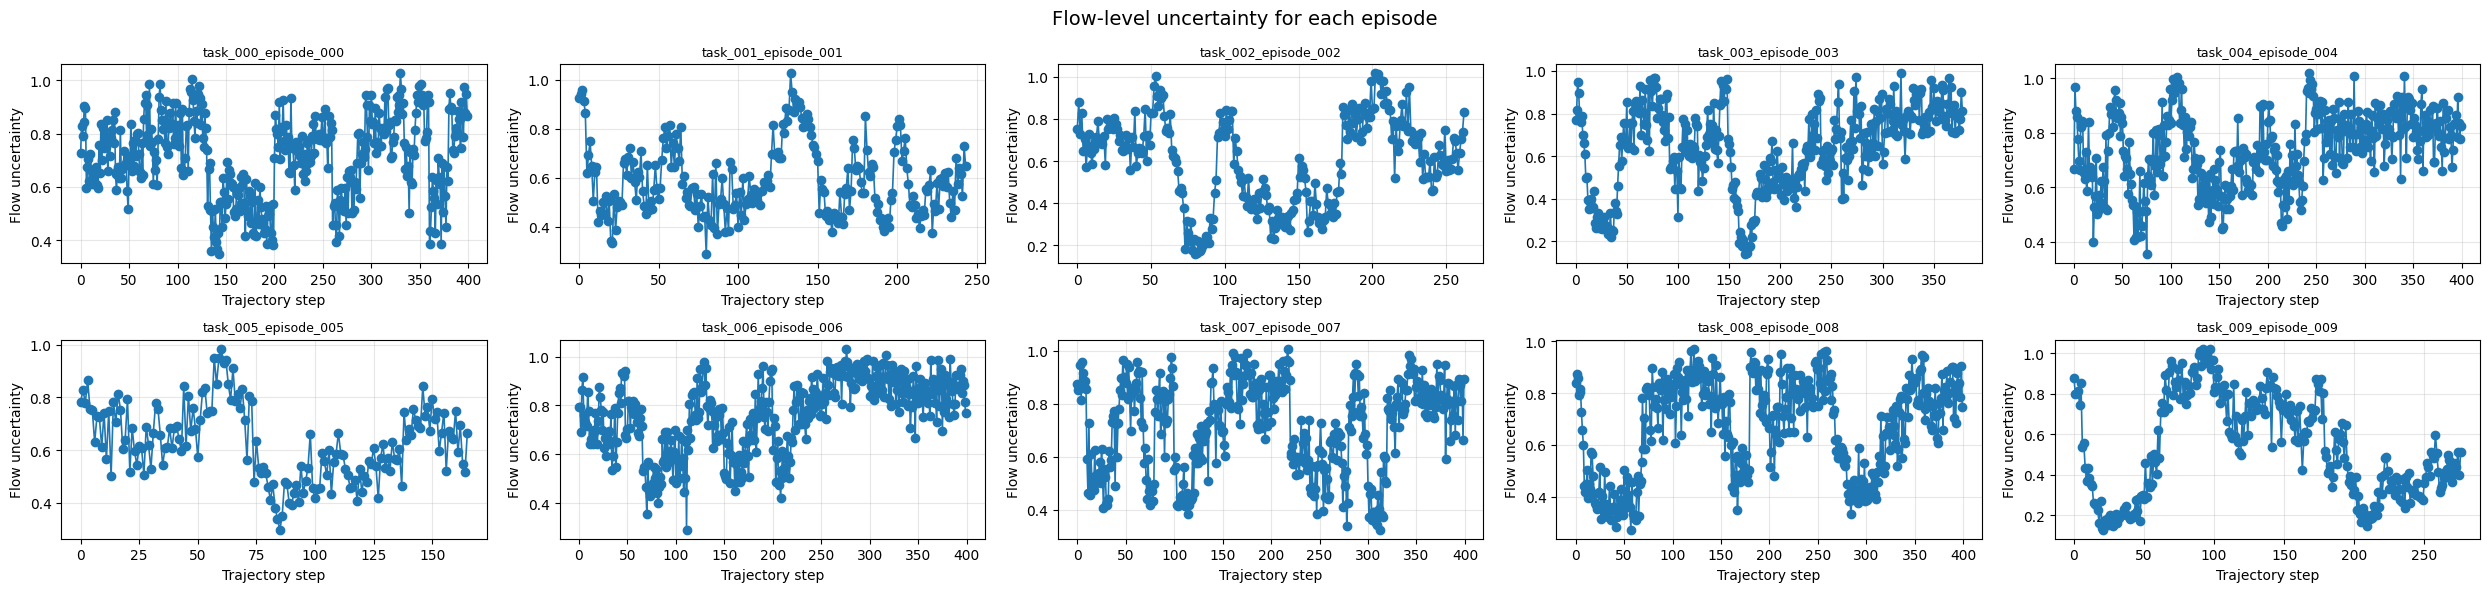

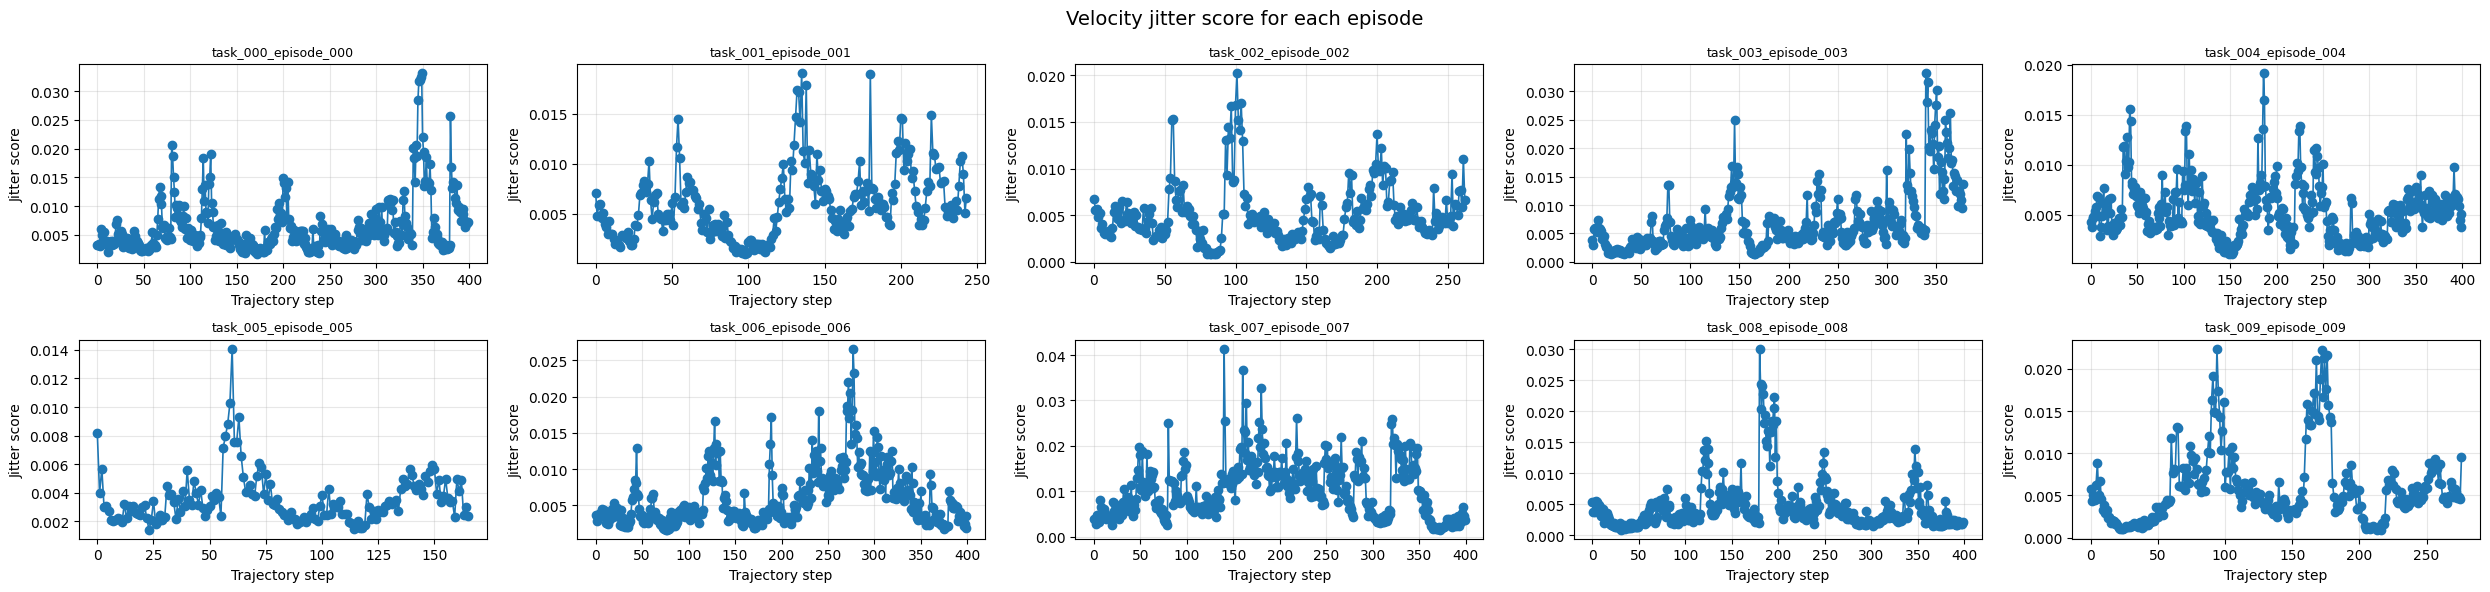

In [66]:
plot_all_npz_h_summary(
    npz_dir="../outputs/libero_long_eval_1/episodes_npz",
    ncols=5,
    save_path="./out/h_summary_long_1.png",
)

In [35]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt


def analyze_action_uncertainty(actions, action_dim_names=None):
    """
    actions: [steps, batch, action_dims]
    """
    actions = np.asarray(actions)

    if actions.ndim != 3:
        raise ValueError(
            f"Expected actions shape [steps, batch, action_dims], got {actions.shape}"
        )

    T, B, D = actions.shape

    if action_dim_names is None:
        if D == 7:
            action_dim_names = ["dx", "dy", "dz", "dRx", "dRy", "dRz", "grip"]
        elif D == 6:
            action_dim_names = ["dx", "dy", "dz", "dRx", "dRy", "dRz"]
        elif D == 4:
            action_dim_names = ["dx", "dy", "dz", "grip"]
        else:
            action_dim_names = [f"dim{i}" for i in range(D)]

    mean_action = actions.mean(axis=1)          # [T, D]
    var_action = actions.var(axis=1)            # [T, D]
    std_action = actions.std(axis=1)            # [T, D]

    step_uncertainty_var = var_action.mean(axis=1)       # [T]
    step_uncertainty_std = std_action.mean(axis=1)       # [T]
    step_uncertainty_max_dim = var_action.max(axis=1)    # [T]

    range_action = actions.max(axis=1) - actions.min(axis=1)  # [T, D]
    step_uncertainty_range = range_action.mean(axis=1)        # [T]

    return {
        "shape": {
            "steps": T,
            "batch": B,
            "action_dims": D,
        },
        "mean_action": mean_action,
        "var_action": var_action,
        "std_action": std_action,
        "range_action": range_action,
        "step_uncertainty_var": step_uncertainty_var,
        "step_uncertainty_std": step_uncertainty_std,
        "step_uncertainty_max_dim": step_uncertainty_max_dim,
        "step_uncertainty_range": step_uncertainty_range,
        "action_dim_names": action_dim_names,
    }


def load_and_analyze_all_npz(
    folder="../outputs/libero_eval_velocities_1/episodes_npz",
    action_key="raw_actions",
    action_dims=slice(0, 6),
):
    """
    Batch analyze all npz files in a folder.

    Expected raw_actions shape:
        [steps, batch, action_dims]
    """
    file_paths = sorted(glob.glob(os.path.join(folder, "*.npz")))

    if len(file_paths) == 0:
        raise FileNotFoundError(f"No .npz files found in {folder}")

    all_reports = {}

    for path in file_paths:
        name = os.path.basename(path).replace(".npz", "")

        try:
            data = np.load(path, allow_pickle=True)

            if action_key not in data:
                print(f"[Skip] {name}: key '{action_key}' not found")
                continue

            actions = data[action_key][:, :, action_dims]
            report = analyze_action_uncertainty(actions)

            success = bool(data["success"]) if "success" in data else None

            all_reports[name] = {
                "file_path": path,
                "success": success,
                "report": report,
            }

            print(
                f"[OK] {name}: shape={actions.shape}, "
                f"mean_var={report['step_uncertainty_var'].mean():.6f}, "
                f"max_var={report['step_uncertainty_var'].max():.6f}, "
                f"success={success}"
            )

        except Exception as e:
            print(f"[Error] {name}: {e}")

    return all_reports


def plot_all_action_uncertainty(
    all_reports,
    metric="step_uncertainty_std",
    title=None,
    max_plots=None,
):
    """
    Plot one uncertainty curve per episode.

    metric options:
        step_uncertainty_var
        step_uncertainty_std
        step_uncertainty_range
        step_uncertainty_max_dim
    """
    items = list(all_reports.items())

    if max_plots is not None:
        items = items[:max_plots]

    plt.figure(figsize=(14, 5))

    for name, item in items:
        report = item["report"]
        y = report[metric]
        x = np.arange(len(y))

        success = item["success"]
        label = name if success is None else f"{name} | success={success}"

        plt.plot(x, y, label=label, alpha=0.8)

    plt.xlabel("Trajectory step")
    plt.ylabel(metric)

    if title is None:
        title = f"Batch action uncertainty: {metric}"

    plt.title(title)
    plt.grid(True)
    plt.legend(fontsize=8, ncol=2)
    plt.tight_layout()
    plt.show()


def plot_all_action_uncertainty_subplots(
    all_reports,
    metric="step_uncertainty_std",
    cols=2,
    save_path=None,
    dpi=300,
    show=True,
):
    """
    Plot each episode in a separate subplot.

    Args:
        all_reports: dict
        metric: str
            one of:
            - step_uncertainty_var
            - step_uncertainty_std
            - step_uncertainty_range
            - step_uncertainty_max_dim
        cols: int
            number of subplot columns
        save_path: str or None
            if not None, save figure to this path
        dpi: int
            figure save dpi
        show: bool
            whether to display the figure
    """
    items = list(all_reports.items())
    n = len(items)
    rows = int(np.ceil(n / cols))

    plt.figure(figsize=(7 * cols, 3 * rows))

    for idx, (name, item) in enumerate(items):
        plt.subplot(rows, cols, idx + 1)

        report = item["report"]
        y = report[metric]
        x = np.arange(len(y))

        success = item["success"]
        title = name if success is None else f"{name} | success={success}"

        plt.plot(x, y)
        plt.title(title)
        plt.xlabel("Trajectory step")
        plt.ylabel(metric)
        plt.grid(True)

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=dpi, bbox_inches="tight")
        print(f"Figure saved to: {save_path}")

    if show:
        plt.show()
    else:
        plt.close()

def summarize_action_uncertainty(all_reports, metric="step_uncertainty_std"):
    """
    Return a sorted summary table as a list of dicts.
    """
    rows = []

    for name, item in all_reports.items():
        y = item["report"][metric]

        rows.append({
            "episode": name,
            "success": item["success"],
            "mean": float(np.nanmean(y)),
            "max": float(np.nanmax(y)),
            "std": float(np.nanstd(y)),
            "length": int(len(y)),
        })

    rows = sorted(rows, key=lambda r: r["mean"], reverse=True)

    print(f"\nSummary sorted by mean {metric}:")
    for r in rows:
        print(
            f"{r['episode']:25s} "
            f"success={str(r['success']):5s} "
            f"mean={r['mean']:.6f} "
            f"max={r['max']:.6f} "
            f"std={r['std']:.6f} "
            f"len={r['length']}"
        )

    return rows

[OK] task_000_episode_000: shape=(400, 15, 7), mean_var=0.058082, max_var=0.400876, success=False
[OK] task_001_episode_001: shape=(244, 15, 7), mean_var=0.082459, max_var=0.233361, success=True
[OK] task_002_episode_002: shape=(263, 15, 7), mean_var=0.090433, max_var=0.603906, success=True
[OK] task_003_episode_003: shape=(379, 15, 7), mean_var=0.090699, max_var=0.379833, success=True
[OK] task_004_episode_004: shape=(400, 15, 7), mean_var=0.046602, max_var=0.209255, success=False
[OK] task_005_episode_005: shape=(166, 15, 7), mean_var=0.053768, max_var=0.176347, success=True
[OK] task_006_episode_006: shape=(400, 15, 7), mean_var=0.062353, max_var=0.219546, success=False
[OK] task_007_episode_007: shape=(400, 15, 7), mean_var=0.074463, max_var=0.281884, success=False
[OK] task_008_episode_008: shape=(400, 15, 7), mean_var=0.054023, max_var=0.458851, success=False
[OK] task_009_episode_009: shape=(277, 15, 7), mean_var=0.132519, max_var=0.460576, success=True

Summary sorted by mean s

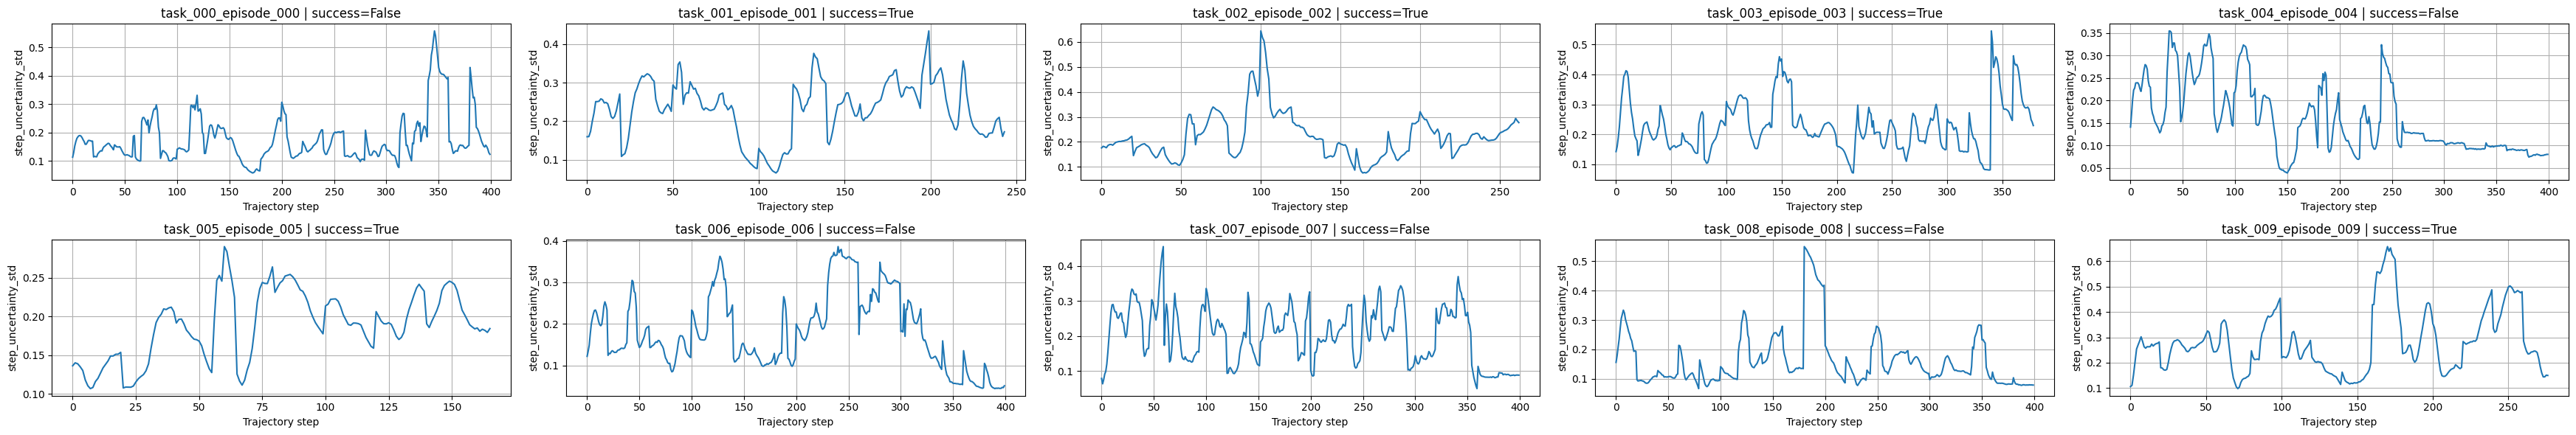

In [56]:
folder = "../outputs/libero_long_eval_1/episodes_npz"

all_reports = load_and_analyze_all_npz(
    folder=folder,
    action_key="raw_actions",
    action_dims=slice(0, 7),   # 只看 dx,dy,dz,dRx,dRy,dRz
)

summary = summarize_action_uncertainty(
    all_reports,
    metric="step_uncertainty_std",
)


plot_all_action_uncertainty_subplots(
    all_reports,
    metric="step_uncertainty_std",
    cols=5,
    save_path="./action_uncertainty_subplots_libero_long_1.png",
)

In [101]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import math


def compute_action_uncertainty_per_h(
    actions,
    action_dims=slice(0, 7),
    metric="std",
):
    """
    Compute action uncertainty for each action chunk / step h.

    Supported shapes:
        [H, B, D]
        [H, N, B, D]

    Returns:
        action_uncertainty: [H]
    """
    actions = np.asarray(actions, dtype=np.float32)

    if actions.ndim == 3:
        # [H, B, D]
        actions = actions[:, :, action_dims]

        if metric == "var":
            return actions.var(axis=1).mean(axis=1)
        elif metric == "std":
            return actions.std(axis=1).mean(axis=1)
        elif metric == "range":
            return (actions.max(axis=1) - actions.min(axis=1)).mean(axis=1)
        else:
            raise ValueError(f"Unknown metric: {metric}")

    elif actions.ndim == 4:
        # [H, N, B, D]
        actions = actions[:, :, :, action_dims]

        if metric == "var":
            return actions.var(axis=2).mean(axis=(1, 2))
        elif metric == "std":
            return actions.std(axis=2).mean(axis=(1, 2))
        elif metric == "range":
            return (actions.max(axis=2) - actions.min(axis=2)).mean(axis=(1, 2))
        else:
            raise ValueError(f"Unknown metric: {metric}")

    else:
        raise ValueError(f"Unsupported raw_actions shape: {actions.shape}")


def reports_to_arrays(reports_h):
    h_list = np.asarray([r["h"] for r in reports_h])
    flow_uncertainties = np.asarray([r["flow_uncertainty"] for r in reports_h], dtype=np.float32)
    jitter_scores = np.asarray([r["jitter_score"] for r in reports_h], dtype=np.float32)
    return h_list, flow_uncertainties, jitter_scores


def plot_all_npz_action_uncertainty_and_jitter(
    npz_dir="../outputs/libero_eval_velocities_4/episodes_npz",
    ncols=3,
    figsize_per_plot=(5, 3.5),
    max_files=None,
    save_path=None,
    action_key="raw_actions",
    velocity_key="velocitys",
    action_dims=slice(0, 7),
    action_uncertainty_metric="std",
):
    """
    In each subplot:
      - left y-axis: action uncertainty
      - right y-axis: jitter score
    """

    npz_dir = Path(npz_dir)
    files = sorted(npz_dir.glob("*.npz"))

    if max_files is not None:
        files = files[:max_files]

    if len(files) == 0:
        print(f"No npz files found in: {npz_dir}")
        return

    n_files = len(files)
    nrows = math.ceil(n_files / ncols)

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(figsize_per_plot[0] * ncols, figsize_per_plot[1] * nrows),
        squeeze=False,
    )

    for idx, file_path in enumerate(files):
        row = idx // ncols
        col = idx % ncols
        ax1 = axes[row][col]

        data = np.load(file_path, allow_pickle=True)

        if action_key not in data:
            ax1.set_title(f"{file_path.stem}\nmissing {action_key}", fontsize=9)
            ax1.axis("off")
            continue

        if velocity_key not in data:
            ax1.set_title(f"{file_path.stem}\nmissing {velocity_key}", fontsize=9)
            ax1.axis("off")
            continue

        # ---------- action uncertainty ----------
        raw_actions = data[action_key]
        action_uncertainty = compute_action_uncertainty_per_h(
            raw_actions,
            action_dims=action_dims,
            metric=action_uncertainty_metric,
        )

        # ---------- jitter score ----------
        velocities_numpy = data[velocity_key][:, :, :1, :7]
        velocities_numpy = np.asarray(velocities_numpy, dtype=np.float32)

        reports_h = analyze_each_h_velocity(velocities_numpy)
        h_list, _, jitter_scores = reports_to_arrays(reports_h)

        # 对齐长度
        min_len = min(len(h_list), len(action_uncertainty), len(jitter_scores))
        h_list = h_list[:min_len]
        action_uncertainty = action_uncertainty[:min_len]
        jitter_scores = jitter_scores[:min_len]

        # ---------- left axis: action uncertainty ----------
        line1 = ax1.plot(
            h_list,
            action_uncertainty,
            # marker="o",
            # linewidth=1.2,
            color="tab:blue",
            label="Action uncertainty",
            # fontsize=8,
        )
        ax1.set_xlabel("Trajectory step")
        ax1.set_ylabel(f"Action uncertainty ({action_uncertainty_metric})", color="tab:blue")
        ax1.tick_params(axis="y", labelcolor="tab:blue")
        ax1.grid(True, alpha=0.3)

        # ---------- right axis: jitter score ----------
        ax2 = ax1.twinx()
        line2 = ax2.plot(
            h_list,
            jitter_scores,
            # marker="o",
            # linewidth=1.2,
            color="tab:orange",
            label="velocity score",
            # fontsize=8,
        )
        ax2.set_ylabel("velocity score", color="tab:orange",)
        ax2.tick_params(axis="y", labelcolor="tab:orange")

        ax1.set_title(file_path.stem, fontsize=9)

        # 合并图例
        lines = line1 + line2
        labels = [l.get_label() for l in lines]
        ax1.legend(lines, labels, fontsize=9, loc="best")

    # 删除空白 subplot
    for idx in range(n_files, nrows * ncols):
        row = idx // ncols
        col = idx % ncols
        fig.delaxes(axes[row][col])

    fig.suptitle("Action Uncertainty and Jitter Score for Each Episode", fontsize=14)
    fig.tight_layout()

    if save_path is not None:
        save_path = Path(save_path)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved to: {save_path}")

    plt.show()

/tmp/ipykernel_1753714/1116110387.py:77: RuntimeWarning: Mean of empty slice
  flow_uncertainty = np.nanmean(disagreement_per_step)


Figure saved to: out/libero_object_1_action_uncertainty_jitter_subplots.png


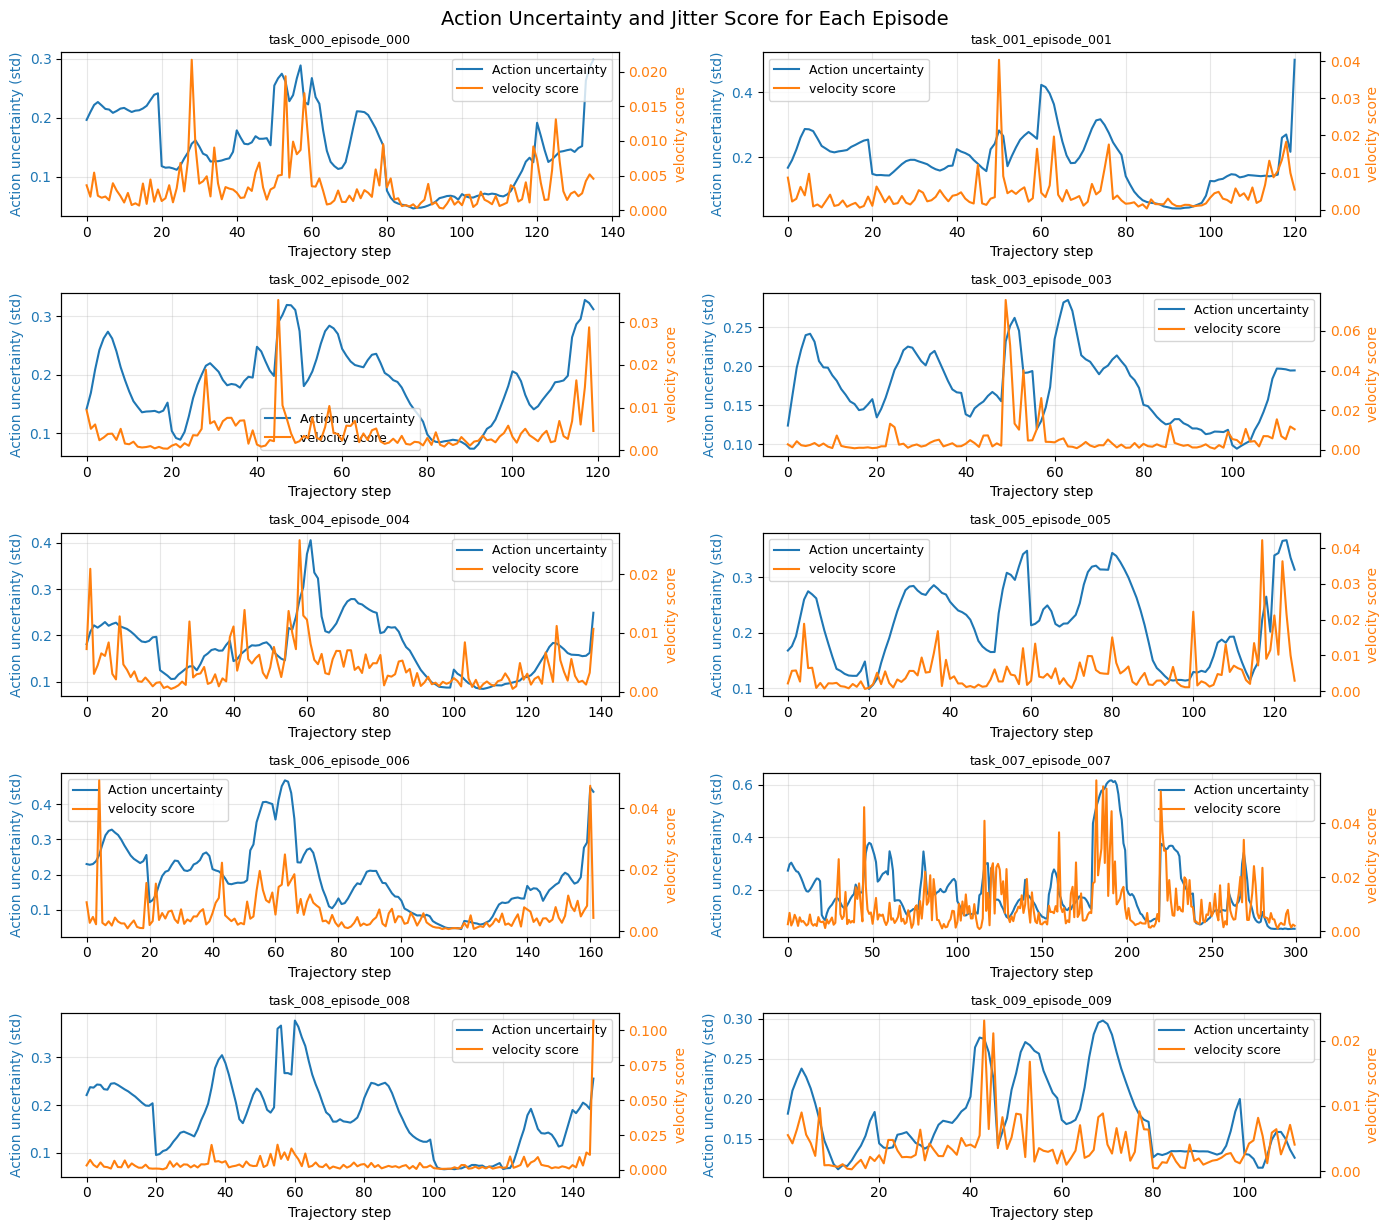

In [110]:
plot_all_npz_action_uncertainty_and_jitter(
    npz_dir="../outputs/libero_object_eval_1/episodes_npz",
    ncols=2,
    figsize_per_plot=(7, 2.5),
    action_uncertainty_metric="std",
    save_path="out/libero_object_1_action_uncertainty_jitter_subplots.png",
)

In [104]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import math

try:
    from scipy.stats import pearsonr, spearmanr
    SCIPY_AVAILABLE = True
except ImportError:
    SCIPY_AVAILABLE = False


def compute_action_uncertainty_per_h(
    actions,
    action_dims=slice(0, 7),
    metric="std",
):
    """
    Compute action uncertainty for each action chunk / trajectory step h.

    Supported shapes:
        [H, B, D]
        [H, N, B, D]

    Returns:
        action_uncertainty: [H]
    """
    actions = np.asarray(actions, dtype=np.float32)

    if actions.ndim == 3:
        # [H, B, D]
        actions = actions[:, :, action_dims]  # [H, B, D]

        if metric == "var":
            # variance over batch, then average over action dims
            return actions.var(axis=1).mean(axis=1)  # [H]

        elif metric == "std":
            return actions.std(axis=1).mean(axis=1)  # [H]

        elif metric == "range":
            return (actions.max(axis=1) - actions.min(axis=1)).mean(axis=1)

        else:
            raise ValueError(f"Unknown metric: {metric}")

    elif actions.ndim == 4:
        # [H, N, B, D]
        actions = actions[:, :, :, action_dims]  # [H, N, B, D]

        if metric == "var":
            # variance over batch B, then average over denoise/sample step N and action dims D
            return actions.var(axis=2).mean(axis=(1, 2))  # [H]

        elif metric == "std":
            return actions.std(axis=2).mean(axis=(1, 2))  # [H]

        elif metric == "range":
            return (actions.max(axis=2) - actions.min(axis=2)).mean(axis=(1, 2))

        else:
            raise ValueError(f"Unknown metric: {metric}")

    else:
        raise ValueError(f"Unsupported raw_actions shape: {actions.shape}")


def safe_corr(x, y):
    """
    Return Pearson and Spearman correlation.
    """
    x = np.asarray(x, dtype=np.float32)
    y = np.asarray(y, dtype=np.float32)

    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]

    if len(x) < 2:
        return {
            "n": len(x),
            "pearson": np.nan,
            "pearson_p": np.nan,
            "spearman": np.nan,
            "spearman_p": np.nan,
        }

    if SCIPY_AVAILABLE:
        pearson_val, pearson_p = pearsonr(x, y)
        spearman_val, spearman_p = spearmanr(x, y)
    else:
        pearson_val = np.corrcoef(x, y)[0, 1]
        pearson_p = np.nan
        spearman_val = np.nan
        spearman_p = np.nan

    return {
        "n": len(x),
        "pearson": float(pearson_val),
        "pearson_p": float(pearson_p),
        "spearman": float(spearman_val),
        "spearman_p": float(spearman_p),
    }


def analyze_action_uncertainty_jitter_correlation(
    npz_dir="../outputs/libero_eval_velocities_4/episodes_npz",
    action_key="raw_actions",
    velocity_key="velocitys",
    action_dims=slice(0, 7),
    action_uncertainty_metric="std",
    max_files=None,
    save_path=None,
    show=True,
):
    """
    For each npz:
        compute action uncertainty per h
        compute jitter_score per h
        compute correlation

    Also compute global correlation over all episodes.
    """
    npz_dir = Path(npz_dir)
    files = sorted(npz_dir.glob("*.npz"))

    if max_files is not None:
        files = files[:max_files]

    if len(files) == 0:
        print(f"No npz files found in: {npz_dir}")
        return None

    all_action_unc = []
    all_jitter = []
    episode_results = {}

    for file_path in files:
        data = np.load(file_path, allow_pickle=True)

        if action_key not in data:
            print(f"[Skip] {file_path.name}: no {action_key} key")
            continue

        if velocity_key not in data:
            print(f"[Skip] {file_path.name}: no {velocity_key} key")
            continue

        raw_actions = data[action_key]
        velocities_numpy = data[velocity_key][:, :, :1, :7]
        velocities_numpy = np.asarray(velocities_numpy, dtype=np.float32)

        # action uncertainty: [H]
        action_uncertainty = compute_action_uncertainty_per_h(
            raw_actions,
            action_dims=action_dims,
            metric=action_uncertainty_metric,
        )

        # jitter score: [H]
        reports_h = analyze_each_h_velocity(velocities_numpy)
        h_list, flow_uncertainties, jitter_scores = reports_to_arrays(reports_h)

        # 防止长度不一致
        min_len = min(len(action_uncertainty), len(jitter_scores))
        action_uncertainty = action_uncertainty[:min_len]
        jitter_scores = jitter_scores[:min_len]
        h_list = h_list[:min_len]

        corr = safe_corr(action_uncertainty, jitter_scores)

        episode_results[file_path.stem] = {
            "h": h_list,
            "action_uncertainty": action_uncertainty,
            "jitter_score": jitter_scores,
            "corr": corr,
        }

        all_action_unc.append(action_uncertainty)
        all_jitter.append(jitter_scores)

        print(
            f"[{file_path.stem}] "
            f"n={corr['n']}, "
            f"Pearson={corr['pearson']:.4f}, p={corr['pearson_p']:.4e}, "
            f"Spearman={corr['spearman']:.4f}, p={corr['spearman_p']:.4e}"
        )

    if len(all_action_unc) == 0:
        print("No valid episodes found.")
        return None

    all_action_unc = np.concatenate(all_action_unc)
    all_jitter = np.concatenate(all_jitter)

    global_corr = safe_corr(all_action_unc, all_jitter)

    print("\n==============================")
    print("Global correlation")
    print("==============================")
    print(f"n = {global_corr['n']}")
    print(f"Pearson correlation : {global_corr['pearson']:.4f}, p = {global_corr['pearson_p']:.4e}")
    print(f"Spearman correlation: {global_corr['spearman']:.4f}, p = {global_corr['spearman_p']:.4e}")

    # -------------------------
    # Global scatter plot
    # -------------------------
    plt.figure(figsize=(6, 5))
    plt.scatter(all_action_unc, all_jitter, alpha=0.6)

    plt.xlabel(f"Action uncertainty ({action_uncertainty_metric})")
    plt.ylabel("Jitter score")
    plt.title(
        "Action uncertainty vs. jitter score\n"
        f"Pearson={global_corr['pearson']:.3f}, "
        f"Spearman={global_corr['spearman']:.3f}"
    )
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    if save_path is not None:
        save_path = Path(save_path)
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Saved scatter plot to: {save_path}")

    if show:
        plt.show()
    else:
        plt.close()

    return {
        "episode_results": episode_results,
        "global_action_uncertainty": all_action_unc,
        "global_jitter_score": all_jitter,
        "global_corr": global_corr,
    }

/tmp/ipykernel_1753714/1116110387.py:77: RuntimeWarning: Mean of empty slice
  flow_uncertainty = np.nanmean(disagreement_per_step)


[task_000_episode_000] n=136, Pearson=0.3610, p=1.5755e-05, Spearman=0.4961, p=8.1951e-10
[task_001_episode_001] n=121, Pearson=0.3350, p=1.7251e-04, Spearman=0.3795, p=1.7608e-05
[task_002_episode_002] n=120, Pearson=0.4676, p=7.2540e-08, Spearman=0.5184, p=1.3250e-09
[task_003_episode_003] n=115, Pearson=0.1803, p=5.3765e-02, Spearman=0.1098, p=2.4264e-01
[task_004_episode_004] n=139, Pearson=0.4894, p=9.7404e-10, Spearman=0.6108, p=1.4194e-15
[task_005_episode_005] n=126, Pearson=0.3588, p=3.6925e-05, Spearman=0.4709, p=2.6247e-08
[task_006_episode_006] n=162, Pearson=0.5235, p=8.8298e-13, Spearman=0.5285, p=4.8907e-13
[task_007_episode_007] n=300, Pearson=0.5363, p=9.7829e-24, Spearman=0.4044, p=3.1155e-13
[task_008_episode_008] n=147, Pearson=0.2485, p=2.4056e-03, Spearman=0.4829, p=5.8394e-10
[task_009_episode_009] n=112, Pearson=0.4379, p=1.3759e-06, Spearman=0.4840, p=6.4207e-08

Global correlation
n = 1478
Pearson correlation : 0.4241, p = 0.0000e+00
Spearman correlation: 0.40

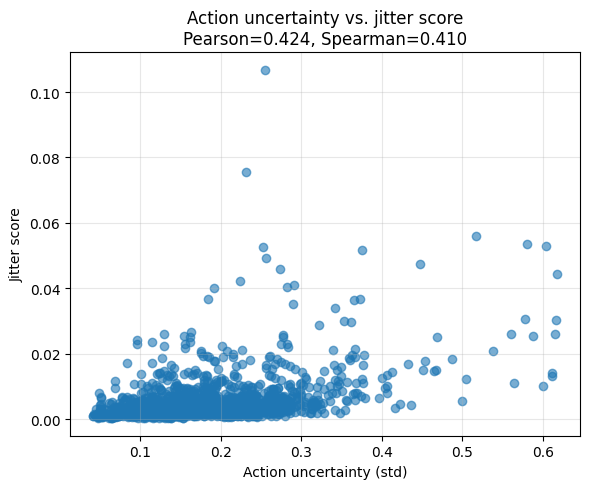

In [109]:
results = analyze_action_uncertainty_jitter_correlation(
    npz_dir="../outputs/libero_object_eval_1/episodes_npz",
    action_key="raw_actions",
    velocity_key="velocitys",
    action_dims=slice(0, 7),
    action_uncertainty_metric="std",
    save_path="./out/libero_object_1_action_uncertainty_vs_jitter.png",
)